# Sorting Network Sets

Frequently a set of `Networks` is recorded while changing some other variable; like voltage, or current or time. So... now you have this set of data  and you want to look at how some feature evolves, or calculate some representative  statistics. This example demonstrates how to do this using [NetworkSets](../../tutorials/NetworkSet.ipynb).

## Generate some Data

For the purpose of this example we use a predefined `skrf.media.Media` object to generate some networks, and save them as a series of touchstone files. Each  file is named with a timestamp, generated with the convenience function `rf.util.now_string()`.

In [1]:
from time import sleep

import matplotlib.pyplot as plt
import numpy as np

import skrf as rf
from skrf.util import now_string, now_string_2_dt

%matplotlib inline
rf.stylely()


!rm -rf tmp
!mkdir tmp

wg = rf.instances.wr10 # just a dummy media object to generate data

for k in range(10):
    # timestamp generated with `now_string()`
    ntwk = wg.random(name=now_string()+'.s1p')
    ntwk.s = k*ntwk.s
    ntwk.write_touchstone(dir='tmp')
    sleep(.1)

Lets take a look at what we made

In [2]:
!ls tmp

2026.11.15.12.27.43.096615.s1p	2026.11.15.12.27.43.614947.s1p
2026.11.15.12.27.43.199835.s1p	2026.11.15.12.27.43.718788.s1p
2026.11.15.12.27.43.303446.s1p	2026.11.15.12.27.43.822645.s1p
2026.11.15.12.27.43.407438.s1p	2026.11.15.12.27.43.926583.s1p
2026.11.15.12.27.43.511033.s1p	2026.11.15.12.27.44.030429.s1p


## Not sorted (default)

When created using `NetworkSet.from_dir()`, the `NetworkSet`'s stores each `Network` randomly

In [3]:
ns = rf.networkSet.NetworkSet.from_dir('tmp')
ns.ntwk_set

[1-Port Network: '2026.11.15.12.27.43.096615',  75.0-110.0 GHz, 1001 pts, z0=[50.+0.j],
 1-Port Network: '2026.11.15.12.27.43.199835',  75.0-110.0 GHz, 1001 pts, z0=[50.+0.j],
 1-Port Network: '2026.11.15.12.27.43.303446',  75.0-110.0 GHz, 1001 pts, z0=[50.+0.j],
 1-Port Network: '2026.11.15.12.27.43.407438',  75.0-110.0 GHz, 1001 pts, z0=[50.+0.j],
 1-Port Network: '2026.11.15.12.27.43.511033',  75.0-110.0 GHz, 1001 pts, z0=[50.+0.j],
 1-Port Network: '2026.11.15.12.27.43.614947',  75.0-110.0 GHz, 1001 pts, z0=[50.+0.j],
 1-Port Network: '2026.11.15.12.27.43.718788',  75.0-110.0 GHz, 1001 pts, z0=[50.+0.j],
 1-Port Network: '2026.11.15.12.27.43.822645',  75.0-110.0 GHz, 1001 pts, z0=[50.+0.j],
 1-Port Network: '2026.11.15.12.27.43.926583',  75.0-110.0 GHz, 1001 pts, z0=[50.+0.j],
 1-Port Network: '2026.11.15.12.27.44.030429',  75.0-110.0 GHz, 1001 pts, z0=[50.+0.j]]

## Sort it

In [4]:
ns.sort()
ns.ntwk_set

[1-Port Network: '2026.11.15.12.27.43.096615',  75.0-110.0 GHz, 1001 pts, z0=[50.+0.j],
 1-Port Network: '2026.11.15.12.27.43.199835',  75.0-110.0 GHz, 1001 pts, z0=[50.+0.j],
 1-Port Network: '2026.11.15.12.27.43.303446',  75.0-110.0 GHz, 1001 pts, z0=[50.+0.j],
 1-Port Network: '2026.11.15.12.27.43.407438',  75.0-110.0 GHz, 1001 pts, z0=[50.+0.j],
 1-Port Network: '2026.11.15.12.27.43.511033',  75.0-110.0 GHz, 1001 pts, z0=[50.+0.j],
 1-Port Network: '2026.11.15.12.27.43.614947',  75.0-110.0 GHz, 1001 pts, z0=[50.+0.j],
 1-Port Network: '2026.11.15.12.27.43.718788',  75.0-110.0 GHz, 1001 pts, z0=[50.+0.j],
 1-Port Network: '2026.11.15.12.27.43.822645',  75.0-110.0 GHz, 1001 pts, z0=[50.+0.j],
 1-Port Network: '2026.11.15.12.27.43.926583',  75.0-110.0 GHz, 1001 pts, z0=[50.+0.j],
 1-Port Network: '2026.11.15.12.27.44.030429',  75.0-110.0 GHz, 1001 pts, z0=[50.+0.j]]

## Sorting using `key` argument 

You can also pass a function through the `key` argument, which allows you to sort on arbitrary properties. For example, we could sort based on the sub-second field of the name,  

In [5]:
ns = rf.networkSet.NetworkSet.from_dir('tmp')
ns.sort(key = lambda x: x.name.split('.')[0])
ns.ntwk_set

[1-Port Network: '2026.11.15.12.27.43.096615',  75.0-110.0 GHz, 1001 pts, z0=[50.+0.j],
 1-Port Network: '2026.11.15.12.27.43.199835',  75.0-110.0 GHz, 1001 pts, z0=[50.+0.j],
 1-Port Network: '2026.11.15.12.27.43.303446',  75.0-110.0 GHz, 1001 pts, z0=[50.+0.j],
 1-Port Network: '2026.11.15.12.27.43.407438',  75.0-110.0 GHz, 1001 pts, z0=[50.+0.j],
 1-Port Network: '2026.11.15.12.27.43.511033',  75.0-110.0 GHz, 1001 pts, z0=[50.+0.j],
 1-Port Network: '2026.11.15.12.27.43.614947',  75.0-110.0 GHz, 1001 pts, z0=[50.+0.j],
 1-Port Network: '2026.11.15.12.27.43.718788',  75.0-110.0 GHz, 1001 pts, z0=[50.+0.j],
 1-Port Network: '2026.11.15.12.27.43.822645',  75.0-110.0 GHz, 1001 pts, z0=[50.+0.j],
 1-Port Network: '2026.11.15.12.27.43.926583',  75.0-110.0 GHz, 1001 pts, z0=[50.+0.j],
 1-Port Network: '2026.11.15.12.27.44.030429',  75.0-110.0 GHz, 1001 pts, z0=[50.+0.j]]

## Extracting Datetimes

You can also convert the ntwk names to datetime objects, in case you want to plot something with pandas or do some other processing. There is a companion function to `rf.util.now_string()` which is `rf.util.now_string_2_dt()`. How creative..

In [6]:
ns.sort()
dt_idx = [now_string_2_dt(k.name ) for k in ns]
dt_idx

[datetime.datetime(2026, 11, 15, 12, 27, 43, 96615),
 datetime.datetime(2026, 11, 15, 12, 27, 43, 199835),
 datetime.datetime(2026, 11, 15, 12, 27, 43, 303446),
 datetime.datetime(2026, 11, 15, 12, 27, 43, 407438),
 datetime.datetime(2026, 11, 15, 12, 27, 43, 511033),
 datetime.datetime(2026, 11, 15, 12, 27, 43, 614947),
 datetime.datetime(2026, 11, 15, 12, 27, 43, 718788),
 datetime.datetime(2026, 11, 15, 12, 27, 43, 822645),
 datetime.datetime(2026, 11, 15, 12, 27, 43, 926583),
 datetime.datetime(2026, 11, 15, 12, 27, 44, 30429)]

## Put into a Pandas DataFrame and Plot

The next step is to slice the network set along the time axis. For example we may want to look at S11 phase, at a few different frequencies. This can be done with the following script. Note that NetworkSets can be sliced by frequency with human readable strings, just like Networks.

Text(0, 0.5, 'S11 (deg)')

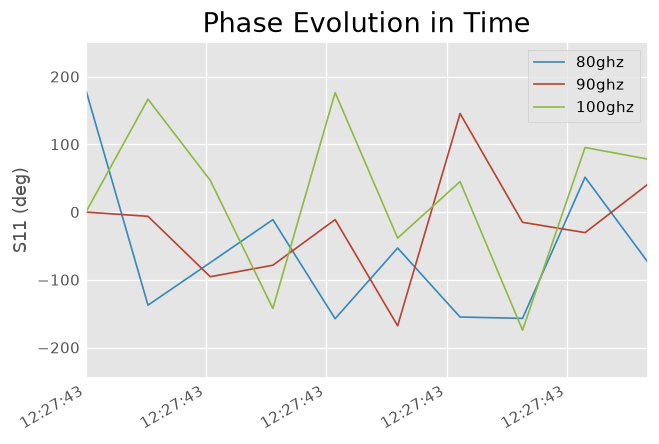

In [7]:
import pandas as pd

dates = pd.DatetimeIndex(dt_idx)

# create a function to pull out S11 in degrees at a specific frequency

s_deg_at = lambda s:{s: [k[s].s_deg[0,0,0] for k in ns]}  # noqa: E731

for f in ['80ghz', '90ghz','100ghz']:
    df =pd.DataFrame(s_deg_at(f), index=dates)
    df.plot(ax=plt.gca())
plt.title('Phase Evolution in Time')
plt.ylabel('S11 (deg)')

## Visualizing Behavior with  `signature`

It may be of use to visualize the evolution of a scalar component of the network set over all frequencies. This can be done with a little bit of array manipulation and `imshow`. For example if we take the magnitude in dB for each network, and create  2D matrix from this,

In [8]:
mat = np.array([k.s_db.flatten() for k in ns])
mat.shape

/home/alex/code/scikit-rf-docs/skrf/mathFunctions.py:303: RuntimeWarning: divide by zero encountered in log10
  out = 20 * np.log10(z)


(10, 1001)

This array has shape  ( 'Number of Networks' , 'Number frequency points'). This can be visualized with imshow. Most of the code below just adds labels, and axis-scales. 

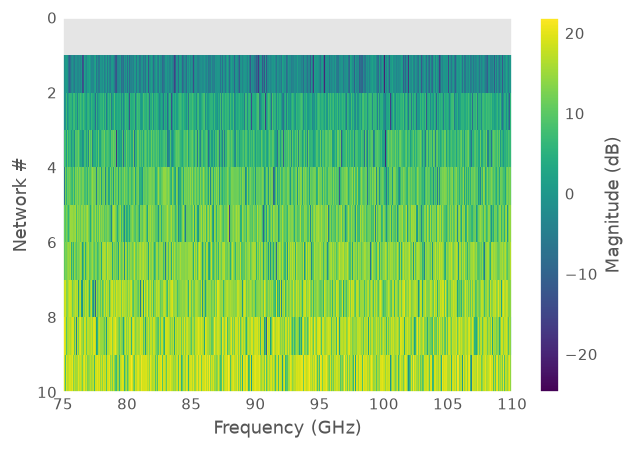

In [9]:
freq = ns[0].frequency

# creates x and y scales
extent = [freq.f_scaled[0], freq.f_scaled[-1], len(ns) ,0]

#make the image
plt.imshow(mat, aspect='auto',extent=extent,interpolation='nearest')

# label things
plt.grid(0)
freq.labelXAxis()
plt.ylabel('Network #')
cbar = plt.colorbar()
cbar.set_label('Magnitude (dB)')

This process is automated with the method `NetworkSet.signature()`. It even has a `vs_time` parameter which will automatically create the DateTime index from the Network's names, if they were written by `rf.now_string()` 

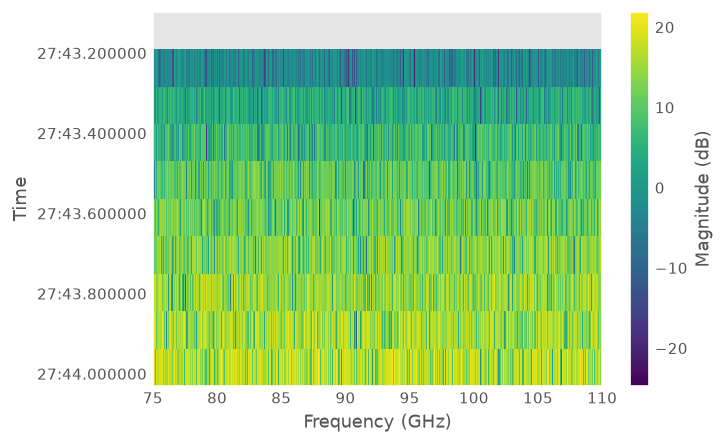

In [10]:
ns.signature(component='s_db', vs_time=True,cbar_label='Magnitude (dB)')